# 01 · Cobertura de las fuentes y selección del universo

**Objetivo.** Documentar cuánta información aportan WDI, V-Dem y MC para los 193 Estados miembros de la ONU, justificar el recorte temporal 2000-2020, los umbrales de cobertura por indicador y la exclusión de países con información insuficiente.

**Insumos.** `data/processed/panel_largo.parquet` (panel país-año-indicador construido por `pipeline/build_dataset.py`), `cobertura_indicadores.csv` y `missingness_pais.csv` (`pipeline/build_features.py`).

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
from inflacion.sources.countries import un_members

members = un_members().set_index("iso3")
panel = pd.read_parquet(D / "panel_largo.parquet")
cov = pd.read_csv(D / "cobertura_indicadores.csv")
cand = cov[cov["dimension"] != "TARGET"].copy()
print(f"Panel: {len(panel):,} observaciones · {panel['codigo'].nunique()} indicadores · {panel['iso3'].nunique()} países · {panel['anio'].min()}-{panel['anio'].max()}")

Panel: 3,553,521 observaciones · 1017 indicadores · 193 países · 1990-2024


## 1. Cobertura temporal por fuente

La cobertura se mide como el porcentaje de celdas país-indicador con dato en cada año, sobre el total posible (193 países × indicadores de la fuente).

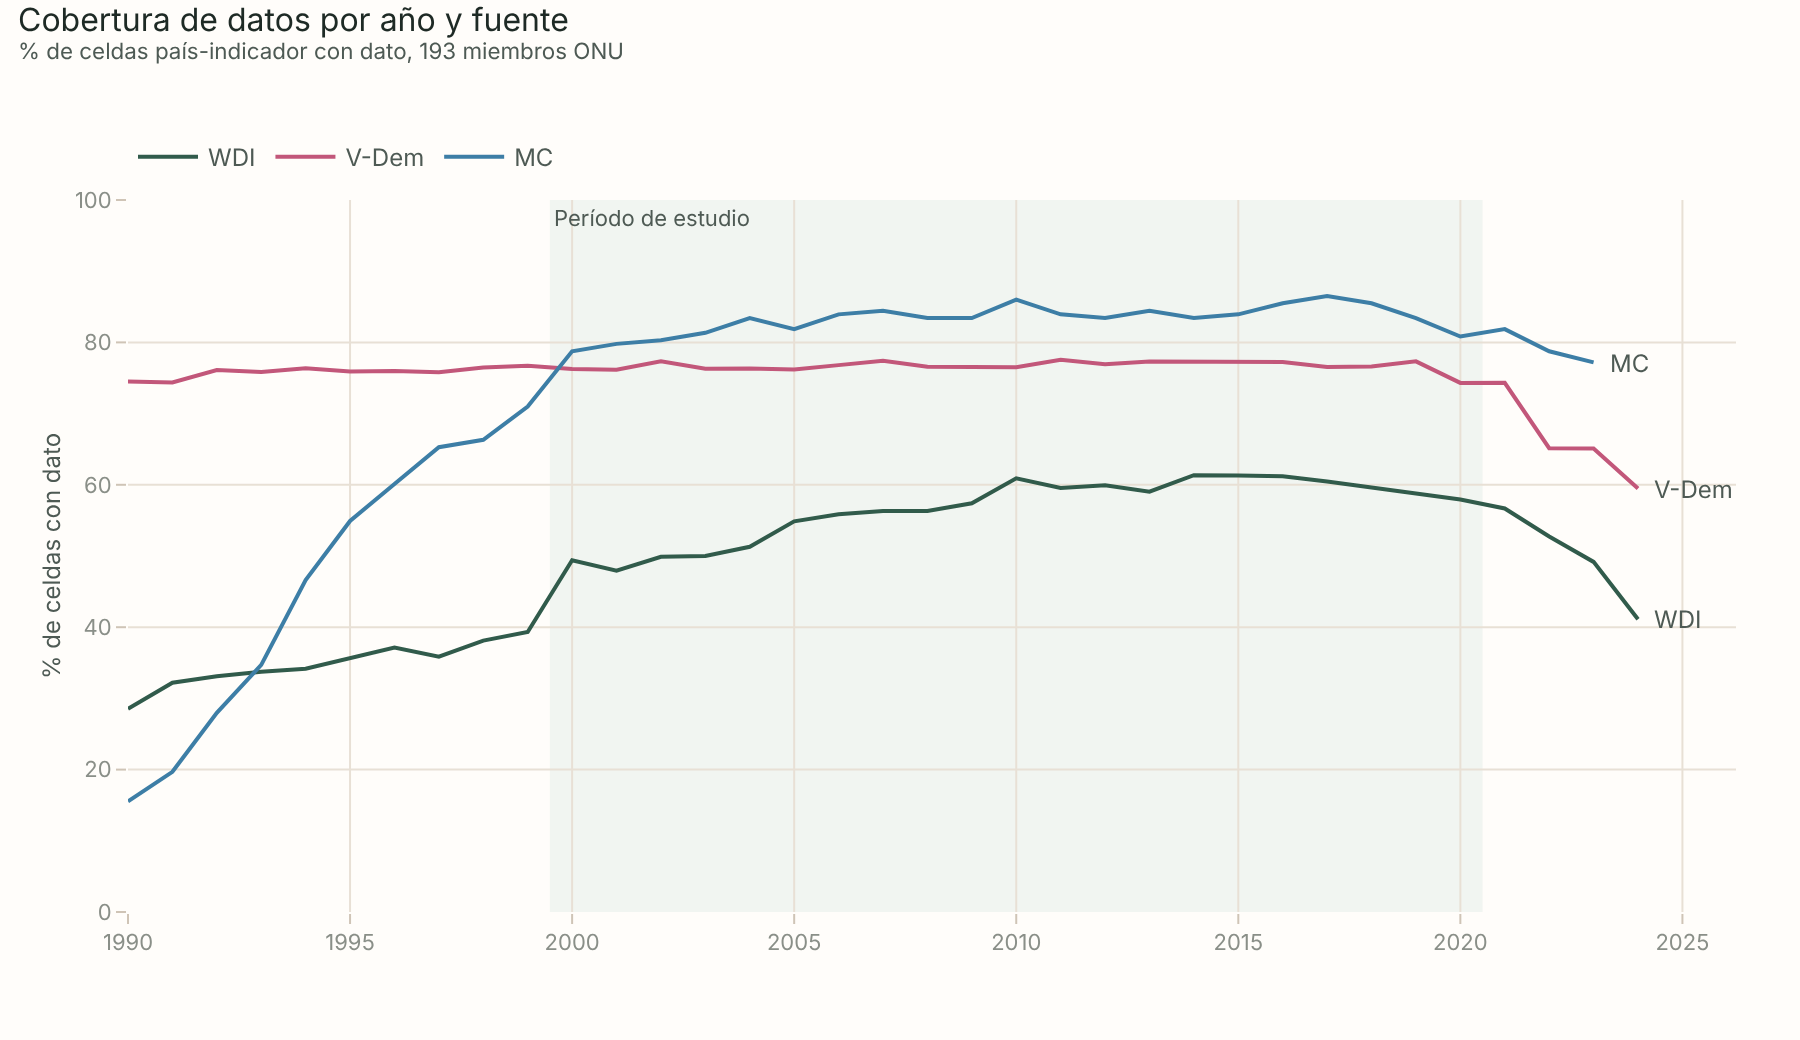

fuente    MC  V-Dem   WDI
anio                     
1990    15.5   74.5  28.5
1995    54.9   75.9  35.7
2000    78.8   76.3  49.4
2010    86.0   76.5  60.9
2020    80.8   74.3  57.9
2022    78.8   65.1  52.7
2024     NaN   59.5  41.1


In [2]:
n_ind = panel[panel["dimension"] != "TARGET"].groupby("fuente")["codigo"].nunique()
by_year = (panel[panel["dimension"] != "TARGET"].groupby(["fuente", "anio"]).size()
           .div(n_ind * 193, level="fuente").mul(100).rename("pct").reset_index())

fig = go.Figure()
fig.add_vrect(x0=1999.5, x1=2020.5, fillcolor=SEQUENTIAL_BLUE[0], opacity=0.5, line_width=0, layer="below",
              annotation_text="Período de estudio", annotation_position="top left",
              annotation_font=dict(size=11, color=INK_SECONDARY))
for i, src in enumerate(["WDI", "V-Dem", "MC"]):
    d = by_year[by_year["fuente"] == src]
    fig.add_scatter(x=d["anio"], y=d["pct"], name=src, mode="lines", line=dict(color=CATEGORICAL[i]),
                    hovertemplate=src + " %{x}: %{y:.1f}%<extra></extra>")
    fig.add_annotation(x=d["anio"].iloc[-1], y=d["pct"].iloc[-1], text=src, showarrow=False, xanchor="left",
                       xshift=6, font=dict(color=INK_SECONDARY))
fig.update_layout(title=subtitle("Cobertura de datos por año y fuente", "% de celdas país-indicador con dato, 193 miembros ONU"),
                  yaxis=dict(title="% de celdas con dato", range=[0, 100]), xaxis_title=None, showlegend=True)
show(fig, "01_cobertura_por_anio")
print(by_year.pivot(index="anio", columns="fuente", values="pct").loc[[1990, 1995, 2000, 2010, 2020, 2022, 2024]].round(1))

**Interpretación.** Las tres fuentes se estabilizan a partir de 2000: MC pasa de 16% de celdas con dato en 1990 a 79% en 2000, y WDI de 29% a 50%. V-Dem, en cambio, es estable desde 1990 (alrededor de 75%). Después de 2020 la cobertura cae en las tres fuentes (WDI 41% y V-Dem 60% en 2024; MC sin datos en 2024). No se trata de una característica de los países: los datos tardan en publicarse y varios índices de V-Dem se actualizan solo con el ciclo electoral. La ventana 2000-2020 es, por lo tanto, el tramo más largo en el que las tres fuentes conviven con cobertura alta y estable.

El nivel absoluto de WDI (alrededor de 60%) es más bajo que el de las otras fuentes porque el denominador incluye todos los indicadores candidatos, también los de cobertura pobre, que el filtro de la sección siguiente elimina.

## 2. Cobertura por indicador

Para cada uno de los indicadores candidatos (clasificados e incluidos tras los filtros de comparabilidad) se calcula, en 2000-2020:

- **% de países** con al menos un dato;
- **% medio de años** cubiertos entre los países que tienen dato.

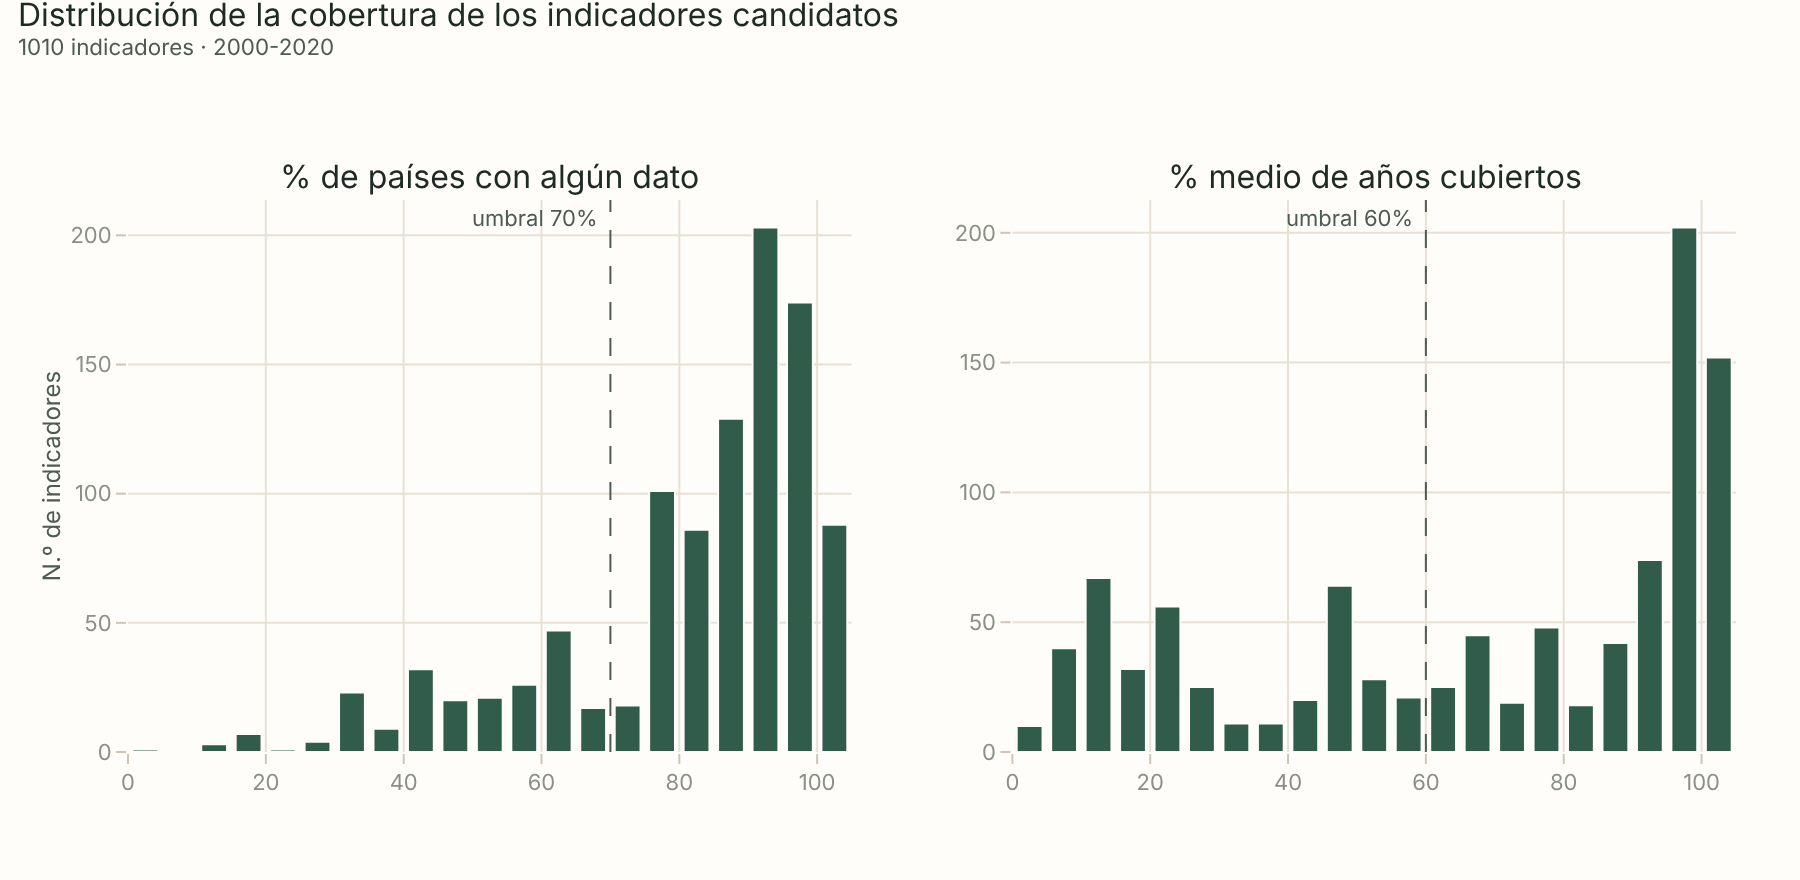

       pct_paises  pct_anios_promedio
count      1010.0              1010.0
mean         82.0                67.1
std          19.2                33.4
min           0.5                 4.8
25%          76.7                40.1
50%          89.1                77.5
75%          96.2                99.0
max         100.0               100.0
Cumplen ambos umbrales: 553 de 1010


In [3]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("% de países con algún dato", "% medio de años cubiertos"),
                    horizontal_spacing=0.1)
for col, (var, thr) in enumerate([("pct_paises", P["cobertura"]["umbral_pct_paises"]),
                                  ("pct_anios_promedio", P["cobertura"]["umbral_pct_anios"])], start=1):
    fig.add_histogram(x=cand[var], xbins=dict(start=0, end=100.01, size=5), marker_color=CATEGORICAL[0],
                      showlegend=False, row=1, col=col, hovertemplate="%{x}: %{y} indicadores<extra></extra>")
    fig.add_vline(x=thr, line=dict(color=INK_SECONDARY, dash="dash", width=1), row=1, col=col)
    fig.add_annotation(x=thr, y=1, yref="y domain" if col == 1 else "y2 domain", text=f"umbral {thr}%",
                       showarrow=False, xanchor="right", xshift=-4, font=dict(size=11, color=INK_SECONDARY), row=1, col=col)
fig.update_yaxes(title_text="N.º de indicadores", row=1, col=1)
fig.update_layout(title=subtitle("Distribución de la cobertura de los indicadores candidatos",
                                 f"{len(cand)} indicadores · 2000-2020"))
show(fig, "01_hist_cobertura_indicadores", height=440)
print(cand[["pct_paises", "pct_anios_promedio"]].describe().round(1))
print("Cumplen ambos umbrales:", int(cand["cumple_umbral"].sum()), "de", len(cand))

**Interpretación.** La cobertura de países es alta para la mayoría de los indicadores (mediana 89%), con una cola larga hacia abajo. La cobertura de años es bimodal: un grupo grande de series casi completas (alrededor de 100%) y otro de series esporádicas (10-25%), típicamente encuestas de hogares o relevamientos puntuales. Esas series esporádicas no permiten estimar tendencia ni volatilidad con un mínimo de confianza. El umbral conjunto (≥70% de países y ≥60% de años) retiene **553 de 1.010 indicadores (55%)**.

## 3. Sensibilidad del umbral por dimensión

¿Cuántos indicadores retiene cada dimensión si se exige más o menos cobertura de países (manteniendo fijo el umbral de años)? Si una dimensión cae mucho antes que las otras, el umbral la penaliza de forma desigual.

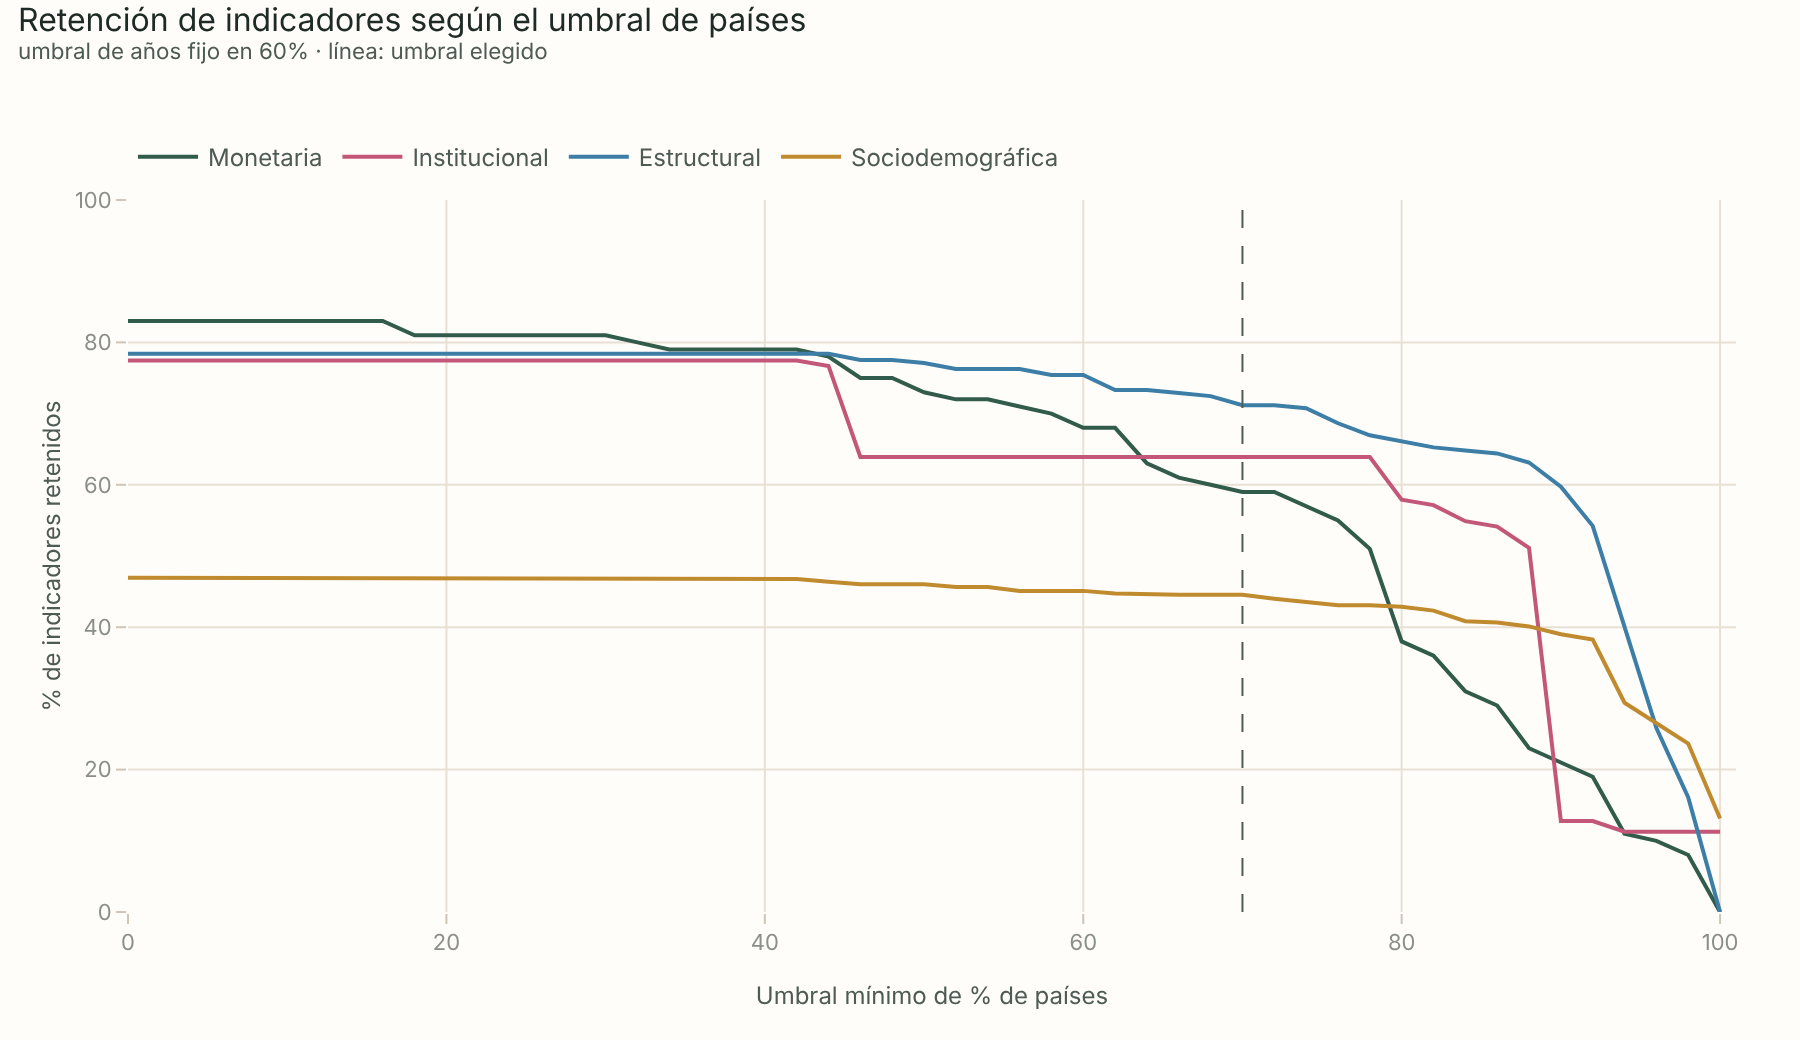

,candidatos,retenidos,pct_retenido
dimension,,,
ESTRUCTURAL,236,168,71.2
INSTITUCIONAL,133,85,63.9
MONETARIA,100,59,59.0
SOCIODEMOGRAFICA,541,241,44.5


In [4]:
grid = np.arange(0, 101, 2)
rows = []
for dim, g in cand.groupby("dimension"):
    ok_years = g["pct_anios_promedio"] >= P["cobertura"]["umbral_pct_anios"]
    for t in grid:
        rows.append({"dimension": dim, "umbral": t, "retenidos_pct": 100 * ((g["pct_paises"] >= t) & ok_years).mean(),
                     "retenidos_n": int(((g["pct_paises"] >= t) & ok_years).sum())})
sens = pd.DataFrame(rows)

fig = go.Figure()
for dim, color in DIMENSION_COLORS.items():
    d = sens[sens["dimension"] == dim]
    fig.add_scatter(x=d["umbral"], y=d["retenidos_pct"], name=DIM_LABELS[dim], mode="lines", line=dict(color=color),
                    customdata=d["retenidos_n"], hovertemplate=DIM_LABELS[dim] + " ≥%{x}%: %{y:.1f}% (%{customdata})<extra></extra>")
fig.add_vline(x=P["cobertura"]["umbral_pct_paises"], line=dict(color=INK_SECONDARY, dash="dash", width=1))
fig.update_layout(title=subtitle("Retención de indicadores según el umbral de países",
                                 f"umbral de años fijo en {P['cobertura']['umbral_pct_anios']}% · línea: umbral elegido"),
                  xaxis=dict(title="Umbral mínimo de % de países", range=[0, 101]), yaxis=dict(title="% de indicadores retenidos", range=[0, 100]))
show(fig, "01_retencion_por_dimension")

tab = cand.groupby("dimension").agg(candidatos=("codigo", "size"), retenidos=("cumple_umbral", "sum"))
tab["pct_retenido"] = 100 * tab["retenidos"] / tab["candidatos"]
tab.round(1)

**Interpretación.** Las curvas son planas hasta un umbral de países del 45% y caen después. El umbral del 70% queda antes de la caída pronunciada de la dimensión monetaria: más allá del 78%, la monetaria pasa a retener menos del 40% de sus indicadores. La sociodemográfica es la más penalizada en términos relativos (45% retenido), por su peso de encuestas puntuales, pero sigue siendo la que más indicadores aporta en términos absolutos (241). La estructural es la que mejor resiste (71%).

**Implicancia.** El universo final no está balanceado entre dimensiones. Esto no se corrige forzando la clasificación: el PCA por dimensión resume cada bloque en componentes, y en las regresiones cada dimensión entra con el mismo número de componentes (notebook 07), de modo que el tamaño de un bloque no le da ventaja en las pruebas.

## 4. Información faltante por país

Con los indicadores que superan el umbral se construye la matriz país × (indicador × estadístico). Un país con una fracción alta de celdas vacías tendría la mayoría de sus valores estimados por imputación, a partir de información propia casi inexistente.

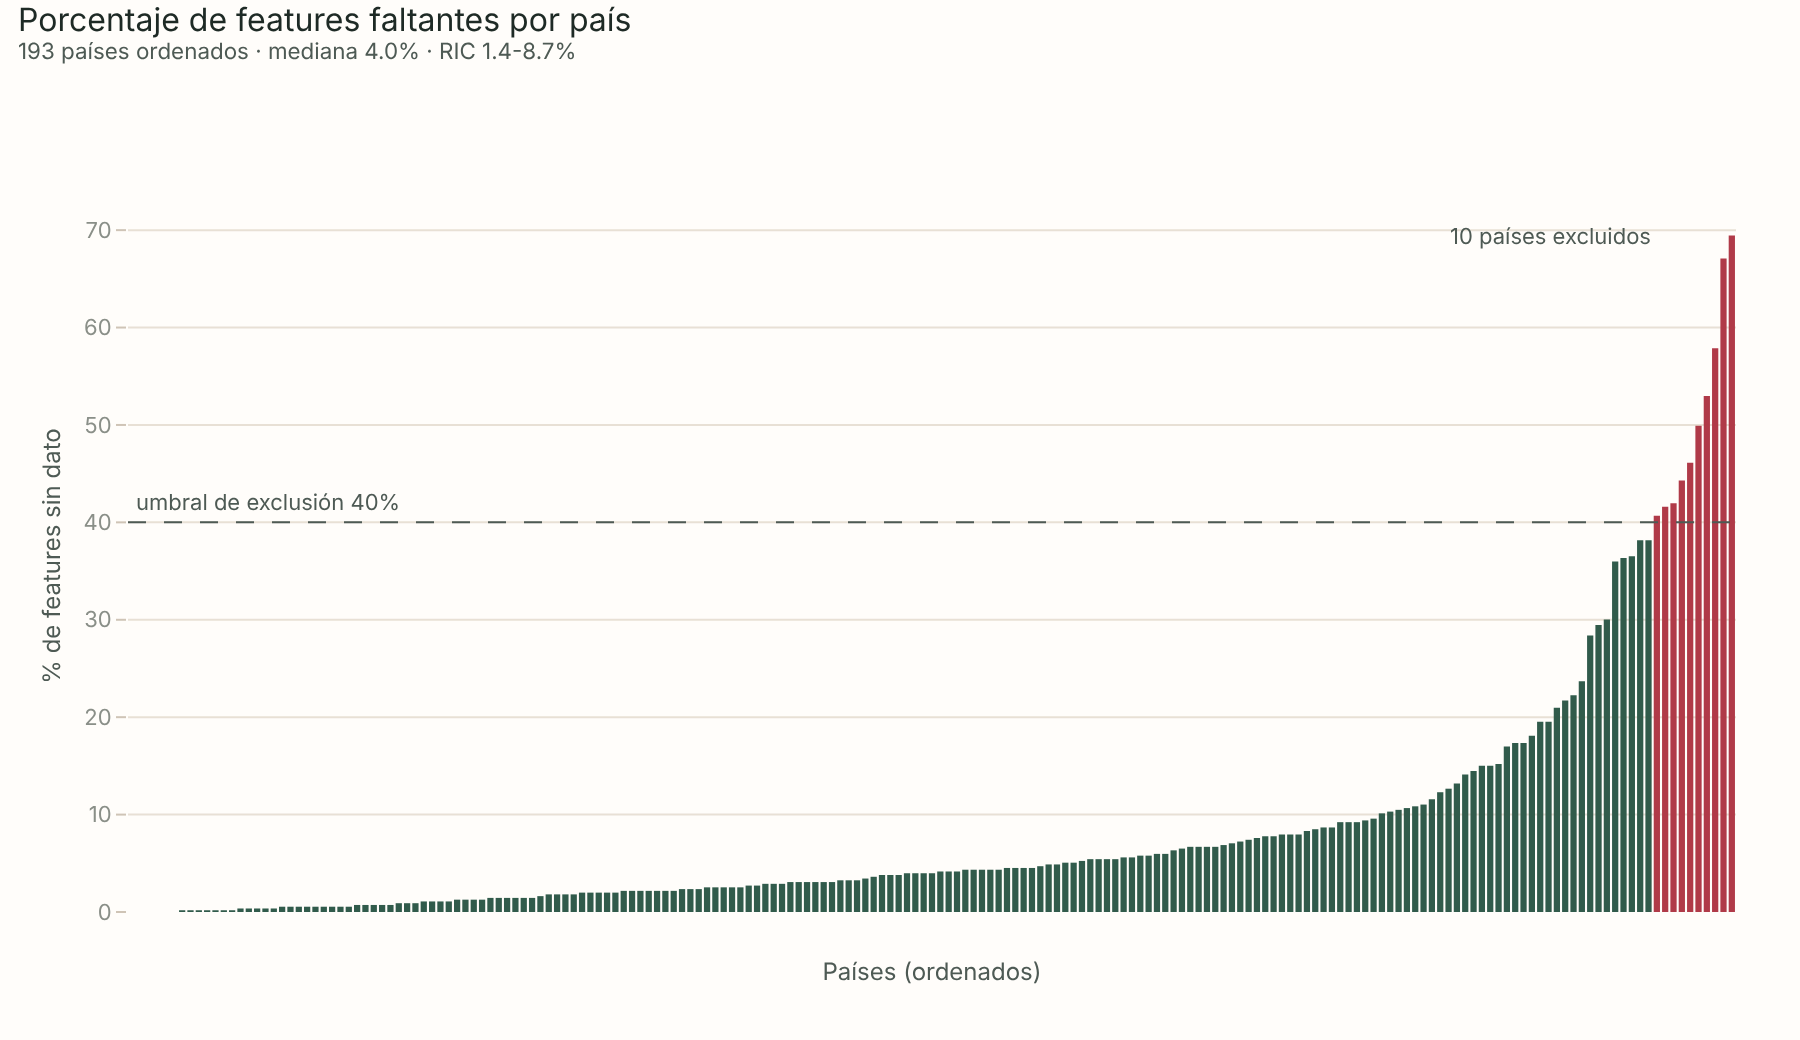

                                       pais  pct_missing
iso3                                                    
MCO                                  Monaco         69.4
LIE                           Liechtenstein         67.1
AND                                 Andorra         57.9
SMR                              San Marino         53.0
TUV                                  Tuvalu         49.9
NRU                                   Nauru         46.1
FSM        Micronesia (Federated States of)         44.3
PRK   Democratic People's Republic of Korea         42.0
PLW                                   Palau         41.6
MHL                        Marshall Islands         40.7
Bigote superior (Q3 + 1.5·RIC): 19.5


In [5]:
miss = pd.read_csv(D / "missingness_pais.csv", index_col="iso3")["pct_missing"].sort_values()
thr = P["paises"]["umbral_missingness_exclusion"]
q1, q3 = miss.quantile([0.25, 0.75])

fig = go.Figure()
fig.add_bar(x=np.arange(len(miss)), y=miss.values, marker_color=np.where(miss > thr, CATEGORICAL[7], CATEGORICAL[0]),
            customdata=members.loc[miss.index, "pais"], hovertemplate="%{customdata}: %{y:.1f}%<extra></extra>", showlegend=False)
fig.add_hline(y=thr, line=dict(color=INK_SECONDARY, dash="dash", width=1))
fig.add_annotation(x=0, y=thr, text=f"umbral de exclusión {thr}%", showarrow=False, xanchor="left", yshift=10,
                   font=dict(size=11, color=INK_SECONDARY))
fig.add_annotation(x=len(miss) - 10, y=miss.max(), text=f"{int((miss > thr).sum())} países excluidos", showarrow=False,
                   xanchor="right", font=dict(size=11, color=INK_SECONDARY))
fig.update_layout(title=subtitle("Porcentaje de features faltantes por país",
                                 f"193 países ordenados · mediana {miss.median():.1f}% · RIC {q1:.1f}-{q3:.1f}%"),
                  xaxis=dict(title="Países (ordenados)", showticklabels=False, showgrid=False, ticks=""), yaxis_title="% de features sin dato")
show(fig, "01_missingness_por_pais")
excl = miss[miss > thr]
print(pd.DataFrame({"pais": members.loc[excl.index, "pais"], "pct_missing": excl.round(1)}).sort_values("pct_missing", ascending=False))
print("Bigote superior (Q3 + 1.5·RIC):", round(q3 + 1.5 * (q3 - q1), 1))

**Interpretación.** La mayoría de los países tiene muy poca información faltante (mediana 4,0%, RIC 1,4-8,7%). Por encima del bigote superior de Tukey (19,5%) aparece una cola de 24 países: pequeños Estados insulares, Estados frágiles y economías poco integradas a los sistemas estadísticos internacionales. Se excluyen solo los **10 países con más del 40% de features vacías**: cuatro microestados europeos (Mónaco, Liechtenstein, Andorra, San Marino), cinco Estados insulares del Pacífico (Tuvalu, Nauru, Micronesia, Palau, Islas Marshall) y Corea del Norte. En ellos la ausencia de datos es estructural, y una imputación basada en vecinos estaría estimando la mayoría de sus valores con información ajena.

El umbral del 40% no es un quiebre estadístico de la distribución. Es una decisión de costo-beneficio: preserva 183 de 193 países (94,8%) y evita imputar países casi vacíos. Los países entre el 20% y el 40% de faltantes se conservan, y su peso en los resultados se revisa en el notebook de robustez a través de la exclusión de atípicos.